## Part I. 1. Imports and Setup

In [315]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [316]:
pd.set_option('display.max_columns', None)

In [317]:
test = pd.read_csv("house-prices/test.csv")
train = pd.read_csv("house-prices/train.csv")

## Part I. 2. Histogram of Continuous and Categorical Features

Three continuous features: LotArea, YearBuilt, GarageArea
Three categorical features: SaleCondition, BldgType, HouseStyle

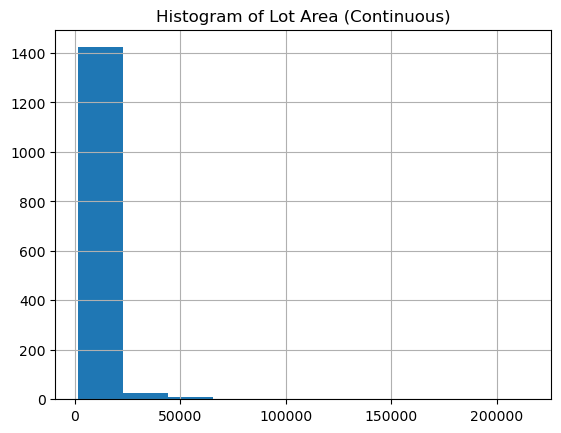

In [321]:
train['LotArea'].hist()
plt.title("Histogram of Lot Area (Continuous)")
plt.show()

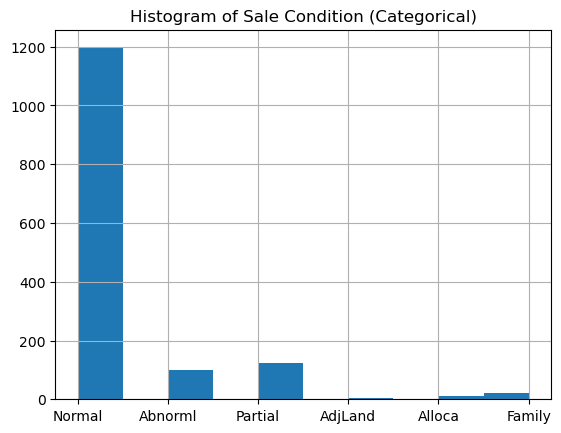

In [322]:
train['SaleCondition'].hist()
plt.title("Histogram of Sale Condition (Categorical)")
plt.show()

## Part I. 3. Pre-Processing

In [324]:
missing_values = (train.isnull().sum())/len(train)
missing_values.sort_values()

Id               0.000000
TotalBsmtSF      0.000000
Heating          0.000000
SaleCondition    0.000000
CentralAir       0.000000
                   ...   
MasVnrType       0.597260
Fence            0.807534
Alley            0.937671
MiscFeature      0.963014
PoolQC           0.995205
Length: 81, dtype: float64

In [325]:
train = train.fillna(0)

I dropped the top 6 columns with most missing values and filled the remaining missing values with 0. Then, I looked at the value counts for the remaining categorical columns. I dropped all categorical columns that were mainly dominated by one category (i.e. >1000 in one category and only 20-30 total spread between the remaining categories) and any categorical column that had too many categories to be successfully one-hot-encoded. Too many categories would lead to too many columns in the final dataset.


In [326]:
## columns dropping because mostly empty
train = train.drop(columns=['Fence','Alley','MiscFeature','PoolQC','FireplaceQu','MasVnrType'])
## columns dropping because mostly 1 category or categorical and not worth encoding
train = train.drop(columns=['Street', 'MSZoning', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope','Condition1',
                            'Condition2','RoofStyle','RoofMatl','Exterior2nd','ExterQual','ExterCond','BsmtQual','BsmtCond',
                            'BsmtExposure','BsmtFinType1','BsmtFinType2','Heating','Electrical','KitchenQual','Functional',
                            'GarageType','GarageQual', 'GarageCond', 'SaleCondition', 'Exterior1st','Foundation','SaleType',"LowQualFinSF",
                           "HeatingQC","PavedDrive","GarageFinish","BldgType"])

In [327]:
#train['BldgType'] = train['BldgType'].replace('Twnhs', 'TwnhsE')
train['CentralAir'] = train['CentralAir'].replace('N', 0)
train['CentralAir'] = train['CentralAir'].replace('Y', 1)

/var/folders/0b/q_x9wxvx2q3d1rbz88_tltnh0000gn/T/ipykernel_57623/1003627857.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train['CentralAir'] = train['CentralAir'].replace('Y', 1)


## Part I. 4. One-Hot-Encoding and histogram of HouseStyle before and after encoding

In [328]:
df_new = pd.get_dummies(train, columns=["Neighborhood","HouseStyle"],dtype=int)
df_new = df_new.set_index('Id')
#df_new

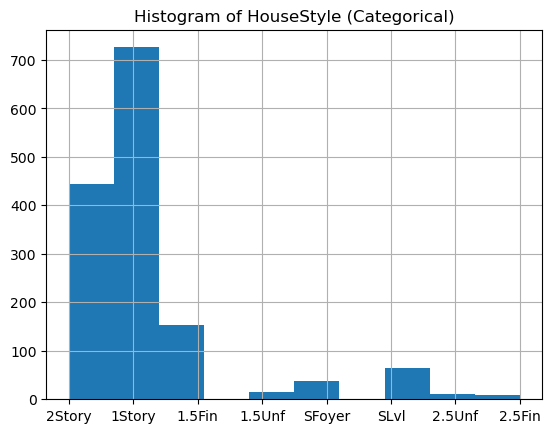

In [329]:
train['HouseStyle'].hist()
plt.title("Histogram of HouseStyle (Categorical)")
plt.show()

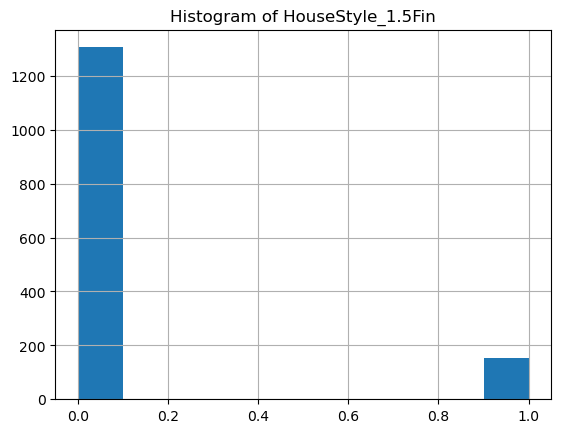

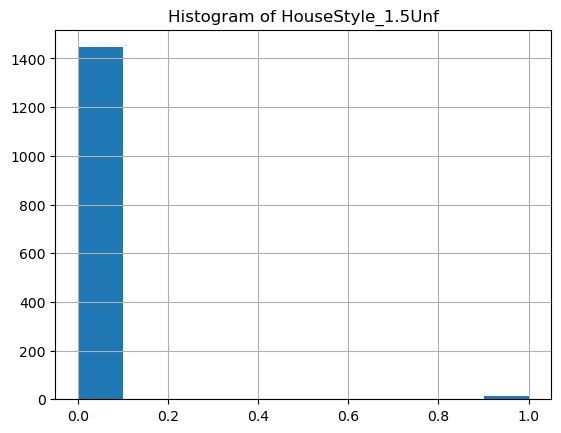

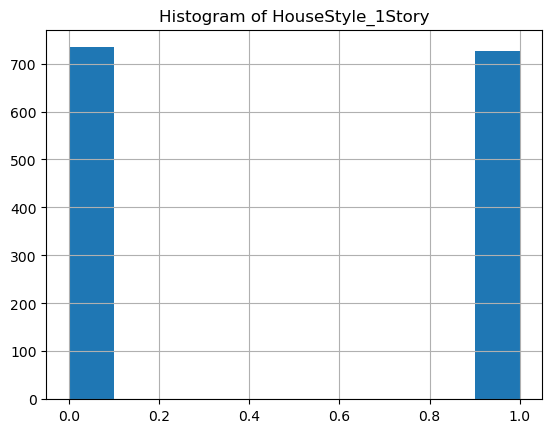

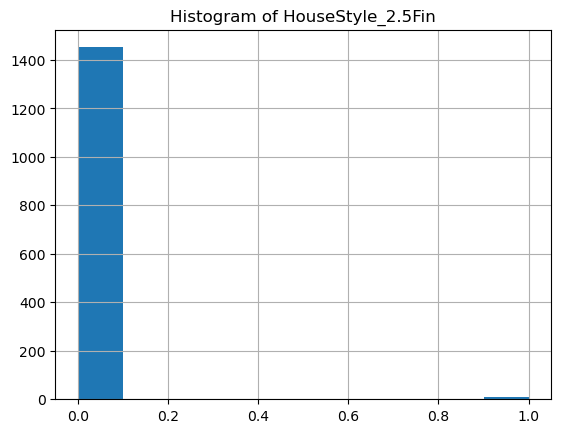

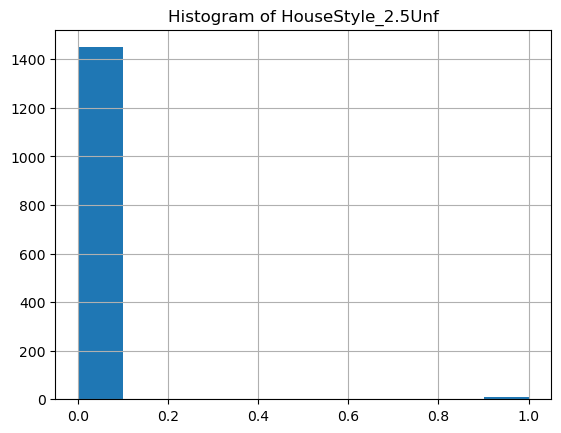

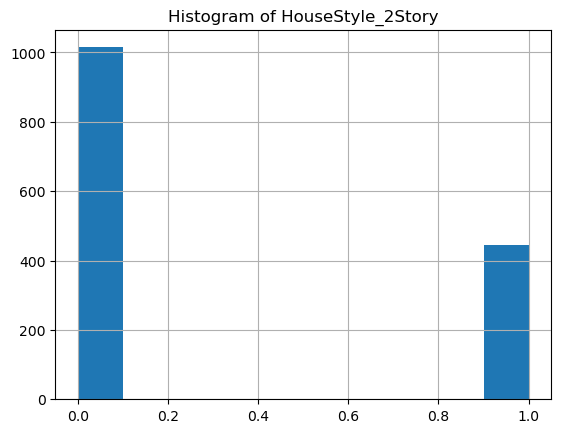

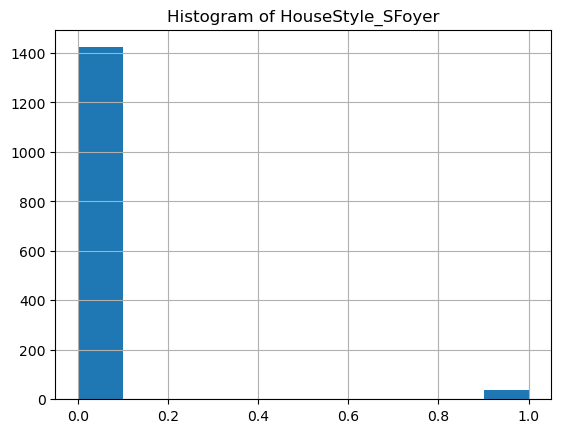

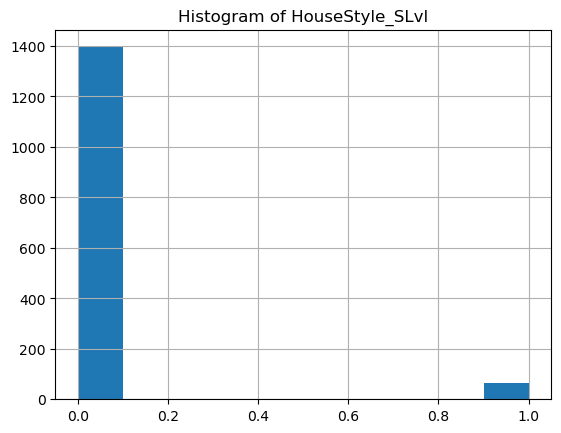

In [330]:
cols = ['HouseStyle_1.5Fin','HouseStyle_1.5Unf','HouseStyle_1Story','HouseStyle_2.5Fin','HouseStyle_2.5Unf','HouseStyle_2Story','HouseStyle_SFoyer','HouseStyle_SLvl']
for i in cols:
    df_new[i].hist()
    plt.title("Histogram of "+ i)
    plt.show()
 

## I. 5. Ordinary Least Squares

In [341]:
y_train = df_new[['SalePrice']]
X_train = df_new.drop(columns=['SalePrice'])

X = np.array(X_train)
y = np.array(y_train).flatten()

X = np.column_stack([np.ones((X.shape[0], 1)), X])

In [345]:
XTX = X.T @ X
XTy = X.T @ y

coefficients = np.linalg.solve(XTX, XTy)
y_pred = X @ coefficients
r2_score(y_train, y_pred)

0.852403937897881

In [347]:
mean_squared_error(y_train, y_pred)

930857159.7081499

## I. 6. Apply Data Cleaning to X_test and test trained model

In [348]:
missing_values = (test.isnull().sum())/len(test)
missing_values.sort_values()

Id             0.000000
Foundation     0.000000
HeatingQC      0.000000
CentralAir     0.000000
Electrical     0.000000
                 ...   
MasVnrType     0.612748
Fence          0.801234
Alley          0.926662
MiscFeature    0.965045
PoolQC         0.997944
Length: 80, dtype: float64

In [349]:
test = test.fillna(0)

In [350]:
## columns dropping because mostly empty
test = test.drop(columns=['Fence','Alley','MiscFeature','PoolQC','FireplaceQu','MasVnrType'])
## columns dropping because mostly 1 category or categorical and not worth encoding
test = test.drop(columns=['Street', 'MSZoning', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope','Condition1',
                            'Condition2','RoofStyle','RoofMatl','Exterior2nd','ExterQual','ExterCond','BsmtQual','BsmtCond',
                            'BsmtExposure','BsmtFinType1','BsmtFinType2','Heating','Electrical','KitchenQual','Functional',
                            'GarageType','GarageQual', 'GarageCond', 'SaleCondition', 'Exterior1st','Foundation','SaleType',"LowQualFinSF",
                           "HeatingQC","PavedDrive","GarageFinish","BldgType"])

In [351]:
test['CentralAir'] = test['CentralAir'].replace('N', 0)
test['CentralAir'] = test['CentralAir'].replace('Y', 1)

/var/folders/0b/q_x9wxvx2q3d1rbz88_tltnh0000gn/T/ipykernel_57623/3213986235.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test['CentralAir'] = test['CentralAir'].replace('Y', 1)


In [381]:
ids = pd.DataFrame(test['Id'])

In [375]:
test_new = pd.get_dummies(test, columns=["Neighborhood","HouseStyle"],dtype=int)
test_new = test_new.set_index('Id')
test_new['HouseStyle_2.5Fin'] = 0

In [376]:
X_test = np.array(test_new)
X_test = np.column_stack([np.ones((X_test.shape[0], 1)), X_test])

In [377]:
y_pred_test = X_test @ coefficients

In [384]:
csv = pd.DataFrame(y_pred_test)
csv.columns = ['SalePrice']
csv = ids.join(csv)

In [385]:
csv

,Id,SalePrice
0,1461,116424.517698
1,1462,150151.389550
2,1463,160034.585349
3,1464,181652.666084
4,1465,243189.534197
...,...,...
1454,2915,72658.126353
1455,2916,63312.255100
1456,2917,175014.954843
1457,2918,90420.239990


In [386]:
csv.to_csv('y_pred.csv', index=False)